# Exercise 3: prompt experiment – Google Flow and OpenAI API

> **Try it yourself in Google Flow:** open [Google Flow](https://labs.google/flow), paste prompts A and B from this notebook and create your own pictures. Images in Google Flow are free. Compare them with the OpenAI pictures below. Do not create videos yet.

## Tasks

1. **One prompt:** write a prompt from building blocks.
2. **Vary:** change one building block of the prompt.
3. **Create:** let the OpenAI API create two pictures per version.
4. **Compare:** rate one feature of the pictures – by eye and with the OpenAI API.

**This is the solution.** Try `image_generation.ipynb` first.

## Setup

Select the **Python 3.11** kernel. The OpenAI API key comes from your `OPENAI_API_KEY` Codespaces secret.

This notebook uses the **OpenAI API** twice: model `gpt-image-1-mini` creates the pictures and model `gpt-6-luna` rates them.

In [1]:
# Standard Python libraries.
import sys

# Libraries installed from requirements.txt.
import pandas as pd
from pydantic import BaseModel

# helper.py is in the main folder, one level up.
sys.path.append("..")

In [2]:
# Functions from helper.py.
from helper import ask, create_pictures, show_images

## 1. Write a prompt from building blocks

Describe what should be visible.

In [3]:
# The building blocks of the prompt.
subject = "a small red wooden rowboat with two oars"
setting = "on a mountain lake"
light = "at dawn, soft light"
composition = "wide shot"

# Prompt A: all blocks in one line.
prompt_a = f"{subject}, {setting}, {light}, {composition}"
print("A:", prompt_a)

A: a small red wooden rowboat with two oars, on a mountain lake, at dawn, soft light, wide shot


## 2. Change one building block

Only **one** block changes, the rest stays the same – so you know what caused the difference.

In [4]:
# Change only the setting: a stormy ocean instead of the mountain lake.
setting = "on a stormy ocean with high waves"

# Prompt B: the same blocks, with the new setting.
prompt_b = f"{subject}, {setting}, {light}, {composition}"
print("B:", prompt_b)

B: a small red wooden rowboat with two oars, on a stormy ocean with high waves, at dawn, soft light, wide shot


## 3. Let the OpenAI API create two pictures per version

The OpenAI API (model `gpt-image-1-mini`, low quality) creates the pictures and saves them in the folder `variants/` next to this notebook. All four cost about US$0.01 together. If you change a prompt and run the cell again, its pictures are created anew. Unchanged pictures are kept, so you do not pay twice.

In [5]:
# Two pictures per version: a_1 and a_2 from prompt A, b_1 and b_2 from prompt B.
names = ["variant_a_1", "variant_a_2", "variant_b_1", "variant_b_2"]
prompts = [prompt_a, prompt_a, prompt_b, prompt_b]

# Create the pictures in variants/ and get their file paths.
paths = create_pictures(names, prompts, "variants")

Unchanged variant_a_1
Unchanged variant_a_2


Created variant_b_1


Created variant_b_2


## 4. Compare the versions by eye

The feature to rate: **does the picture show stormy water – high waves or a dark storm sky?**

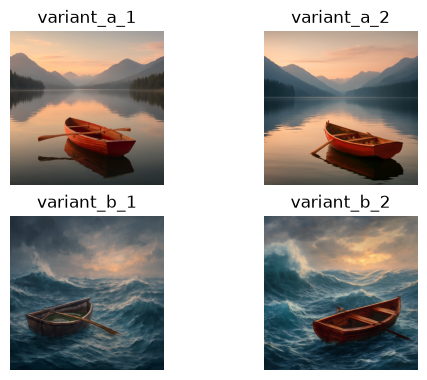

In [6]:
# Version A in the top row, version B in the bottom row.
show_images(paths, columns=2)

In [7]:
# One row per picture.
ratings = pd.DataFrame()
ratings["name"] = names
ratings["version"] = ["A", "A", "B", "B"]

# Your rating per picture: True if the picture shows stormy water.
# Replace these example values with your own.
ratings["me"] = [False, False, True, True]
ratings

,name,version,me
0,variant_a_1,A,False
1,variant_a_2,A,False
2,variant_b_1,B,True
3,variant_b_2,B,True


In [8]:
# Share of pictures with the feature, per version.
# True counts as 1 and False as 0, so the mean is the share of True.
ratings.groupby("version")["me"].mean()

version
A    0.0
B    1.0
Name: me, dtype: float64

## 5. Let the OpenAI API rate the same feature

The same yes/no question for all four pictures, sent to the **OpenAI API** (model `gpt-6-luna`). Does it agree with you?

In [9]:
# The answer format: yes or no, plus a short reason.
class Rating(BaseModel):
    matches: bool
    reason: str

In [10]:
# The same question for every picture.
# The f-string inserts the subject block, so the question follows it.
PROMPT = f"""
The image should show {subject}.
Does it show stormy water, with high waves or a dark storm sky?
Answer false for calm water.
Give a short reason.
"""

In [11]:
# Ask the model about every picture.
api_ratings = []
for path in paths:
    answer = ask(PROMPT, Rating, [path])
    api_ratings.append(answer["matches"])

# Your rating and the OpenAI rating side by side.
ratings["api"] = api_ratings
ratings

,name,version,me,api
0,variant_a_1,A,False,False
1,variant_a_2,A,False,False
2,variant_b_1,B,True,True
3,variant_b_2,B,True,True


In [12]:
# Share of pictures with the feature, per version.
ratings.groupby("version")[["me", "api"]].mean()

,me,api
version,,
A,0.0,0.0
B,1.0,1.0


## Check your understanding

Answer briefly using the outputs above. Try first, then open the hints.

1. Why does the same prompt give different pictures – and what does that mean for your experiment?
2. Why do we change only one building block between version A and version B?
3. With two pictures per version, the share can only be 0, 1/2 or 1. What does this mean for your conclusion?
4. Where do your rating and the OpenAI rating differ? Who is right – and why can you not simply trust the API rating?
5. Google Flow and the OpenAI image API have no seed setting. What do you write down so that someone else can follow your experiment?

**Your answers:**

1. …
2. …
3. …
4. …
5. …

<details>
<summary style="color: #B8860B; font-weight: bold; cursor: pointer;">Hints for self-check</summary>

1. Generation starts from random noise, so every run is different. One picture per version proves nothing. You need several pictures per version and compare the shares.

2. If several blocks change, you cannot tell which one caused the difference. One change per round makes it an experiment instead of trial and error.

3. Two pictures are weak evidence: a single picture moves the share by half. Describe the result as a tendency. A clear conclusion needs more pictures.

4. Look at the pictures where the two ratings differ. Borderline cases – a few waves, a cloudy sky – are hard to judge, for you and for the model. Your own judgement is the reference, so always check a sample by hand.

5. The prompt, the model, the settings (e.g. aspect ratio) and the date. Keep all pictures – also the ones that did not work.

</details>

### Jupyter notebook --footer info--

In [13]:
# Print system and version info for this run.
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1070-azure
Datetime: 2026-11-23 19:11:23
Python Version: 3.11.18
-----------------------------------
